# Load the Plus-Minus dataset using PyTorch

In [1]:
import pennylane as qml
from pennylane import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt

In [2]:
transform=transforms.Compose([
            transforms.Resize(size=18),
            transforms.CenterCrop(size=16),  # optional
            transforms.ToTensor()
        ])

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 
print('Using device:', device)

Using device: cpu


### Convert to NumPy

In [5]:
TRAIN_PATH = './pm_data/dataset_train'
TEST_PATH  = './pm_data/dataset_test'

train = datasets.ImageFolder(root=TRAIN_PATH, transform=transform)
test = datasets.ImageFolder(root=TEST_PATH, transform=transform)
rng = np.random.default_rng(seed=0)    # set seed here for reproducibility
num_classes = 4

train_loader = DataLoader(train, batch_size=len(train))
test_loader = DataLoader(test, batch_size=len(test))

train_img, train_labels = next(iter(train_loader))
train_labels = train_labels.numpy()
test_img, test_labels = next(iter(test_loader))
test_labels = test_labels.numpy()

train_img = np.squeeze(np.delete(arr=train_img.numpy(), obj=[1,2], axis=1))
test_img = np.squeeze(np.delete(arr=test_img.numpy(), obj=[1,2], axis=1))


print(train_img.shape, test_img.shape, train_labels.shape, test_labels.shape)

# permute the arrays so we can visualize different classes with first 10 imgs
rand_idx_train = np.random.permutation(train_img.shape[0])
rand_idx_test = np.random.permutation(test_img.shape[0])

X_train = train_img[rand_idx_train]
Y_train = train_labels[rand_idx_train]

X_test = test_img[rand_idx_test]
Y_test = test_labels[rand_idx_test]

(1000, 16, 16) (200, 16, 16) (1000,) (200,)


### Use PyTorch tensors

In [20]:
"""
TRAIN_PATH = '../pm_data/dataset_train'
TEST_PATH  = '../pm_data/dataset_test'

train = datasets.ImageFolder(root=TRAIN_PATH, transform=transform)
test = datasets.ImageFolder(root=TEST_PATH, transform=transform)
rng = np.random.default_rng(seed=123401234)
num_classes = 4

train_loader = DataLoader(train, batch_size=len(train))
test_loader = DataLoader(test, batch_size=len(test))

train_set_img, train_set_labels = next(iter(train_loader))
test_set_img, test_set_labels = next(iter(test_loader))

train_set_img = torch.squeeze(train_set_img[:,0,:,:])
test_set_img = torch.squeeze(test_set_img[:,0,:,:])


# permute the arrays so we can visualize different classes with first 10 imgs
rand_idx_train = rng.permutation(len(train_set_img))
X_train = train_set_img[rand_idx_train]
Y_train = train_set_labels[rand_idx_train]

rand_idx_test = rng.permutation(len(test_set_img))
X_test = test_set_img[rand_idx_test]
Y_test = test_set_labels[rand_idx_test]
"""

In [6]:
labels_list = ['\u2212', '\u002b', '\uA714', '\u02E7']

def show_images(X, Y):
    num = 10
    images = X[:num]
    labels = Y[:num]
    num_row = 2
    num_col = 5
    fig, axes = plt.subplots(num_row, num_col, figsize=(1.5*num_col,2*num_row))
    for i in range(num):
        ax = axes[i//num_col, i%num_col]
        ax.imshow(images[i], cmap='gray')
        ax.set_title('Label: {}'.format(labels_list[labels[i]]))
    plt.tight_layout()
    plt.show()

Input shapes: X_train_input: (1000, 256), X_test_input: (200, 256),Y_train_input: (1000,), Y_test_input: (200,)
number of samples with label 0 in train set: 250
number of samples with label 1 in train set: 250
number of samples with label 2 in train set: 250
number of samples with label 3 in train set: 250
number of samples with label 0 in test set: 50
number of samples with label 1 in test set: 50
number of samples with label 2 in test set: 50
number of samples with label 3 in test set: 50
first 10 img of train set:


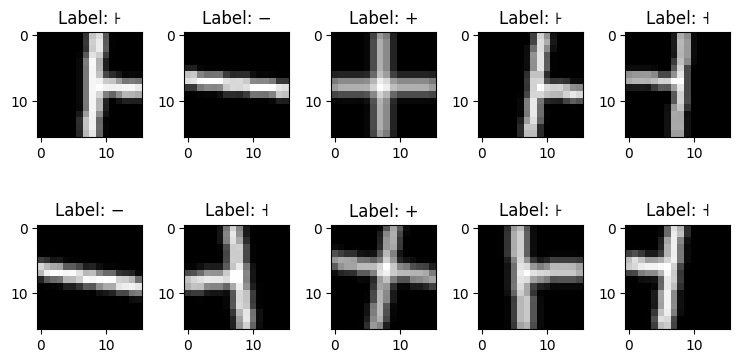

first 10 img of test set:


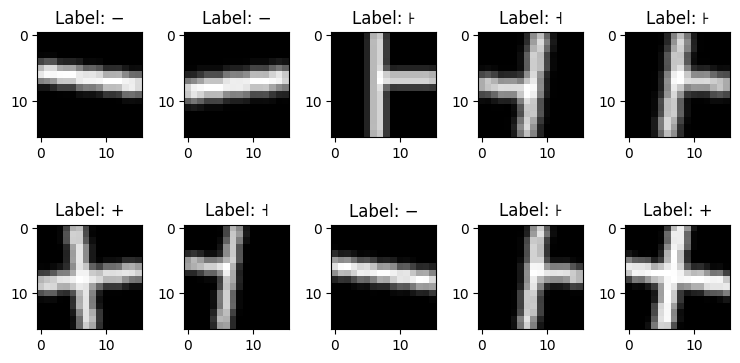

In [7]:
### Visualize some img

classes = [0,1,2,3]
num_classes = len(classes)

def count_occurrences(x,y, set):
    for label in range(len(classes)):
        occurrences = x[y == label].shape[0]
        print(f"number of samples with label {label} in {set} set: {occurrences}")

padding = 0
X_train_input = X_train
Y_train_input = Y_train
X_test_input = X_test
Y_test_input = Y_test

X_train_orig = np.copy(X_train_input)
X_test_orig = np.copy(X_test_input)

X_train_input = np.reshape(X_train_input,(X_train_input.shape[0], -1))
X_test_input = np.reshape(X_test_input,(X_test_input.shape[0], -1))

print(f"Input shapes: X_train_input: {X_train_input.shape}, X_test_input: {X_test_input.shape},"
            +f"Y_train_input: {Y_train_input.shape}, Y_test_input: {Y_test_input.shape}") 

count_occurrences(X_train_input,Y_train_input, "train")
count_occurrences(X_test_input,Y_test_input, "test")

print('first 10 img of train set:')
show_images(X_train_orig, Y_train_input)

print('first 10 img of test set:')
show_images(X_test_orig, Y_test_input)


## Attack sample generation

In [8]:
def FGSM(loss, eps, feats, labels, weights):
    delta = torch.zeros_like(feats, requires_grad=True)
    loss = nn.CrossEntropyLoss()(model(feats + delta), labels)
    loss.backward()
    return eps * delta.grad.detach().sign()

def PGD(model, feats, labels, epsilon=0.1, alpha=0.01, num_iter=10, randomize=False):
    model.train()
    if randomize:
        delta = torch.rand_like(feats, requires_grad=True)
        delta.data = delta.data * 2 * epsilon - epsilon
    else:
        delta = torch.zeros_like(feats, requires_grad=True)
    for t in range(num_iter):
        feats_adv = feats + delta
        outputs = [model(f) for f in feats_adv]
        loss = criterion(torch.stack(outputs),labels)
        loss.backward()
        delta.data = (delta + alpha*delta.grad.detach().sign()).clamp(-epsilon,epsilon)
        delta.grad.zero_()
    return delta.detach()